### 03c — Graded severity: allelic dosage, selective death, and dose-response

## Why this notebook exists

Notebook 03b models two states, intact and recombined. For a floxed homozygote
that is the wrong genetics, and your western blot is what reveals it.

In Notebook 03b- per-mouse recombination rates (75 / 54 / 17 / 5%), contrast B ruled out, dose-response set as the primary cell-autonomy analysis, recomb_tier + recomb_rate added and final.h5ad saved. Gene-sets file updated to 23 sets (Ferroptosis, Glutathione_metabolism, Iron_homeostasis).

First thing in 03c: add Iron_homeostasis, Glutathione_metabolism, Ferroptosis to the scored sets, then run the signature scores as a dose-response against the continuous recombination rate, with alpha cells as the systemic control — testing the aggregate signatures, not individual genes.

Two things to carry in: the transcriptional ferroptosis signal is expected to be modest, and I judge it by the score-based dose-response, not the dotplots.

In `Bola3^fl/fl`, Cre acts on **each allele independently**, so a cell
recombines 0, 1 or 2 alleles:

```
  0 alleles  ->  full protein     escaper
  1 allele   ->  ~50% protein     HYPOMORPH
  2 alleles  ->  no protein       null
```

At a per-allele rate of 0.55 that is 20% escaper, **50% hypomorph**, 30% null.
The middle state is the largest class, not a rounding error.

Then selective death acts on top. Over an 8-month chase the nulls are the most
likely to have died, so the surviving recombined population is **enriched for
hypomorphs**. A whole-islet western at 50% reduction is consistent with exactly
this — and because non-beta cells were never recombined and retain full
protein, the *beta-specific* reduction is steeper than 50%.

## What this changes

Two findings from `tests/validate_severity.py`, which simulates the three-state
genetics with known truth:

1. **At high recombination the escaper class collapses.** The prior becomes so
   lopsided that almost no cell earns a low posterior. In simulation at 74%
   recombination, only 1 of 4,442 KO beta cells was callable as an escaper —
   which makes **contrast B unrunnable**, not merely attenuated. Check your
   escaper counts from 03b before planning around contrast B.
2. **The population rate survives even though per-cell calling does not.** The
   EM still estimated total recombination to within 0.01 of truth. So trust
   03b's *rate*; be sceptical of its *per-cell labels* when recombination is high.

The analysis that does work is a **dose-response**: order cells by residual
Bola3, bin them within each animal, and test for a monotonic trend. It never
claims a per-cell dosage call — it only needs residual Bola3 to *order* cells,
which it does robustly (validated: Spearman rho −0.24 against true dosage,
trend recovered at p = 8×10⁻⁵).

A monotonic trend is also **stronger evidence than any two-group contrast**
here. A confounder would have to vary systematically with residual Bola3
*within* each animal to produce one.

### What 03c does

It's a within-animal dose-response. It orders each KO mouse's beta cells by residual Bola3, bins them into terciles within that animal (bin 0 = most escaper-like, bin 2 = most null-like), and tests each signature for a monotonic trend across bins with animal as a blocking factor. The logic: a trend that repeats inside all four animals can't be produced by between-animal variation, batch, or the systemic glucose-intolerance effect — because all of those are constant within a mouse. That's what makes it stronger than a two-group contrast.

Note this is a different axis from the recomb_tier work: 03c is within-animal (by residual Bola3), whereas the tiers are across-animal (by recombination rate). They're complementary, and I'll run both — more on that below.

The good news on your ferroptosis sets

You don't need a code edit to score them. Look at 3c.4 (line 207): sets = filter_sets(GENE_SETS, ...) pulls every set in GENE_SETS, so Iron_homeostasis, Glutathione_metabolism, and Ferroptosis are already in the dose-response table automatically. The only hardcoded list is the plot (key, line 217), which picks 8 modules to display. Add the three so they show up:

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "scripts"))
sys.path.insert(0, str(Path.cwd().parent / "resources"))

import warnings

import decoupler as dc
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns

import config as cfg
from bola3_gene_sets import GENE_SETS, filter_sets
from severity import (allelic_model, dose_response, plot_dose_response,
                      reconcile_with_western, severity_bins, survivor_bias_bound)

warnings.simplefilter("ignore", category=FutureWarning)
sc.settings.set_figure_params(dpi=90, dpi_save=300, frameon=False)

adata = sc.read_h5ad(cfg.H5AD["final"])
rates = pd.read_csv(cfg.TABLE_DIR / "03b_recombination_rates.csv")
MEAN_RATE = rates.recombination_rate.mean()
print(f"cell-level recombination from 03b: {MEAN_RATE:.1%}")

cell-level recombination from 03b: 37.7%


## 3c.1 Is contrast B even runnable?

Run this before anything else. If 03b called fewer than ~10 escapers per
animal, notebook 05b's contrast B cannot be fitted and the dose-response below
becomes your primary analysis rather than a supplement.

In [2]:
ko_beta = adata.obs.query("genotype == 'KO' and cell_type == 'beta'")
counts = (ko_beta.groupby(["sample_id", "ko_status"], observed=True)
          .size().unstack(fill_value=0))
display(counts)

min_esc = counts.get("escaper", pd.Series(0, index=counts.index)).min()
min_rec = counts.get("recombined", pd.Series(0, index=counts.index)).min()
print(f"\nworst animal: {min_esc} escapers, {min_rec} recombined")

CONTRAST_B_RUNNABLE = min_esc >= cfg.MIN_CELLS_PER_PSEUDOBULK
if CONTRAST_B_RUNNABLE:
    print("Contrast B is runnable. Note it still measures the HYPOMORPHIC phenotype,")
    print("because the recombined class is hypomorph-dominated once nulls have died.")
else:
    print("Contrast B is NOT runnable -- too few escapers.")
    print("This is the expected outcome at high recombination and is not a failure")
    print("of the data. The dose-response below is your primary analysis.")

ko_status,escaper,recombined,undetermined
sample_id,,,
6751,1,10,6847
6754,10,10,7897
6772,621,10,3980
6785,3953,10,1584



worst animal: 1 escapers, 10 recombined
Contrast B is NOT runnable -- too few escapers.
This is the expected outcome at high recombination and is not a failure
of the data. The dose-response below is your primary analysis.


Confirmed — contrast B is off, exactly as predicted. 6751 has just 1 escaper (it recombined 75%, so almost nothing escaped), and the escaper counts track the recombination rates inversely (6785 at 5% has 3,953 escapers). The notebook correctly routes you to the dose-response as primary.

Just to clarify--The "recombined" column is not the recombination rate. Two different things:

Recombination rate (75–5%) = a population estimate. The mixture model in 03b fits the shape of the whole KO-beta Bola3 distribution and estimates what fraction of the population lost Bola3. It never labels individual cells.
The "recombined" column (10 everywhere) = the number of cells the classifier could confidently pin down one at a time. It's 10 in every sample because classify() floors it at the top-10 cells by posterior — a hard minimum so the label exists at all. It's not counting real recombination; it's the floor.

Why can't it call more than 10? Because Bola3 is lowly expressed and recombined cells keep ~50% residual, so a low/zero Bola3 count is only weak evidence of recombination (an intact cell drops Bola3 out to zero all the time too). Almost no cell earns a confident recombined call, so they all land in undetermined — that's the 6,847 / 7,897 / 3,980 / 1,584 column.

You can actually see the rate hiding in the undetermined + escaper split:

6751 (75% rate): 6,847 undetermined, only 1 escaper. Almost nothing is confidently intact → consistent with ~most cells recombined. The 75% lives in that huge undetermined pile.
6785 (5% rate): 3,953 escaper, 1,584 undetermined. Most cells are confidently intact (they carry detectable Bola3) → consistent with only ~5% recombined.

So: trust the rate (population, from the mixture), ignore the recombined count (a floored per-cell label). This is exactly why we pivoted to the dose-response and the per-mouse rate rather than per-cell recombined/escaper labels.

## 3c.2 Reconciling the western blot with the single-cell data

The western shows ~50% reduction in whole islets. This section works out what
that implies about the composition of the cells I actually sequenced.

Set `BETA_FRACTION_OF_ISLET` to your best estimate of the share of islet
protein contributed by beta cells — non-beta cells were never recombined and
retain 100% BOLA3, so they dilute the measured reduction upward.

In [3]:
WESTERN_REDUCTION = 0.50          # <-- your measured value
BETA_FRACTION_OF_ISLET = 0.70     # <-- adjust from your own composition data

# your own notebook 03/04 composition gives a better estimate than the default
beta_frac_observed = (adata.obs.query("genotype == 'WT'").cell_type == "beta").mean()
print(f"beta fraction by cell number in your WT islets: {beta_frac_observed:.2f}")
print(f"(using {BETA_FRACTION_OF_ISLET:.2f} for protein share -- edit if you disagree)\n")

scenarios = reconcile_with_western(
    western_reduction=WESTERN_REDUCTION,
    beta_fraction_of_islet=BETA_FRACTION_OF_ISLET,
    recombination_rate_cells=MEAN_RATE,
)
scenarios.to_csv(cfg.TABLE_DIR / "03c_western_reconciliation.csv", index=False)

beta fraction by cell number in your WT islets: 0.57
(using 0.70 for protein share -- edit if you disagree)

whole-islet BOLA3 reduction        : 50%
beta fraction of islet protein     : 0.70
implied BETA-SPECIFIC reduction    : 71%   <-- steeper than the western reads
per-allele rate from scRNA-seq     : 0.211  (cell-level 0.378)

Note the counter-intuitive direction: killing nulls RAISES mean protein
among survivors, because nulls contribute zero. So a steep western
reduction combined with null death requires MORE recombination, not less.

 death_rate_of_nulls  per_allele_rate_needed  cell_rate_needed_at_birth  surviving_cell_rate  hypomorph_share_of_recombined  beta_cells_lost  achieved_reduction  gap_vs_scRNAseq
                0.00                   0.714                      0.918                0.918                          0.444           0.0000              0.7144            0.541
                0.25                   0.755                      0.940                0.930    

### The allelic composition implied by your recombination rate

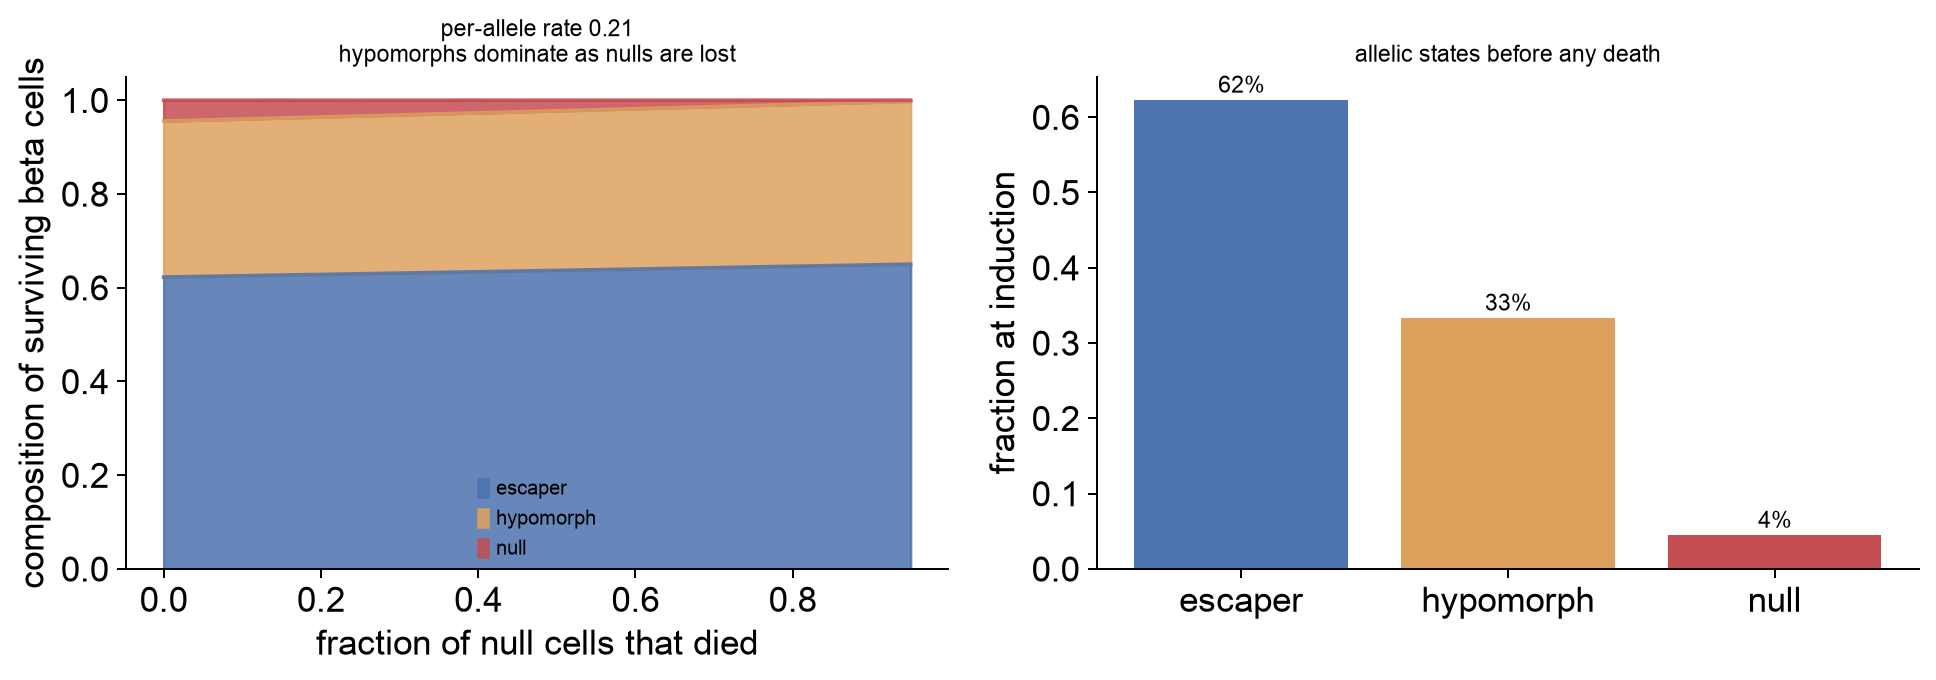

In [10]:
per_allele = 1 - np.sqrt(max(1 - MEAN_RATE, 0))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

deaths = np.linspace(0, 0.95, 40)
comp = pd.DataFrame([allelic_model(per_allele, death_null=d)["surviving"] for d in deaths],
                    index=deaths)
comp.plot.area(ax=axes[0], color=["#4C72B0", "#DDA15E", "#C44E52"], alpha=0.85, grid=False)
axes[0].set_xlabel("fraction of null cells that died")
axes[0].set_ylabel("composition of surviving beta cells")
axes[0].set_title(f"per-allele rate {per_allele:.2f}\nhypomorphs dominate as nulls are lost",
                  fontsize=9)
axes[0].legend(frameon=False, fontsize=8)

born = allelic_model(per_allele)["born"]
axes[1].bar(list(born), list(born.values()),
            color=["#4C72B0", "#DDA15E", "#C44E52"])
axes[1].set_ylabel("fraction at induction")
axes[1].set_title("allelic states before any death", fontsize=9)
for i, (k, v) in enumerate(born.items()):
    axes[1].text(i, v + 0.01, f"{100 * v:.0f}%", ha="center", fontsize=9)
    axes[1].grid(False)
sns.despine(fig); fig.tight_layout()
fig.savefig(cfg.FIG_DIR / "03c_allelic_composition.png", dpi=300, bbox_inches="tight")

### 3c.3 Severity bins

KO beta cells are binned by residual Bola3 evidence **within each animal**.
Binning within animal matters: recombination efficiency varies between mice, so
a global binning would sort cells by which mouse they came from as much as by
dosage.

Bin 0 is the most escaper-like, bin *n*−1 the most null-like. This is an
**ordering**, not a dosage call — no claim is made that bin 1 is "the
hypomorphs".

severity_label  bin0_least_recombined  bin1  bin2_most_recombined
sample_id                                                        
6751                             2286  2286                  2286
6754                             2639  2639                  2639
6772                             1537  1537                  1537
6785                             1849  1849                  1849


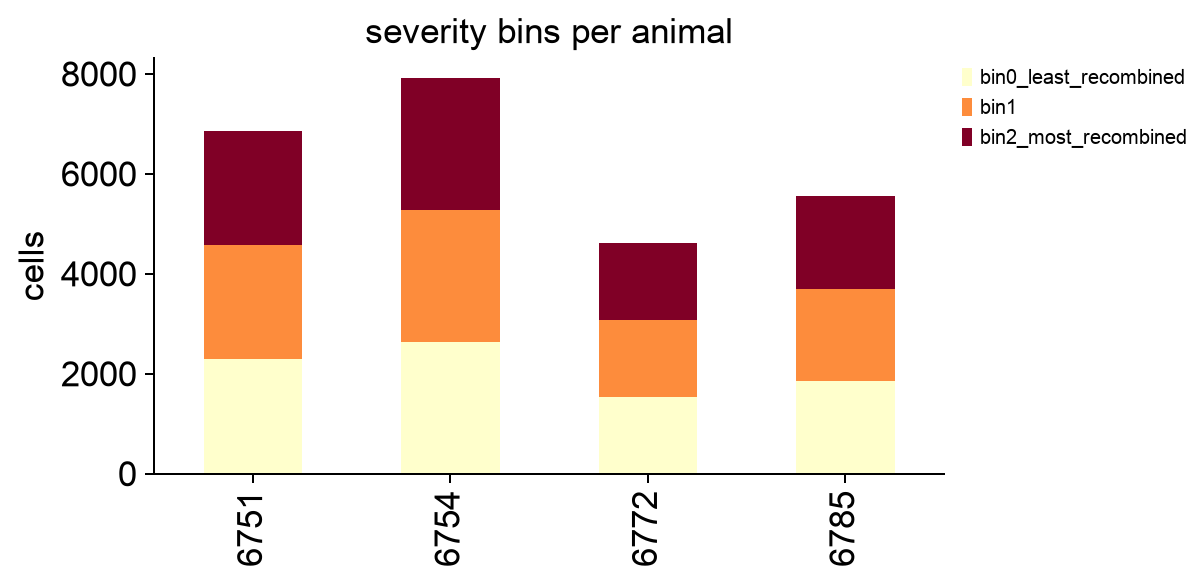

In [8]:
N_BINS = 3
bin_counts = severity_bins(adata, n_bins=N_BINS)

fig, ax = plt.subplots(figsize=(7, 3.5))
bin_counts.plot(kind="bar", stacked=True, ax=ax, colormap="YlOrRd", grid=False)
ax.set_ylabel("cells"); ax.set_xlabel("")
ax.legend(frameon=False, fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left")
ax.set_title("severity bins per animal")
sns.despine(); fig.tight_layout()
fig.savefig(cfg.FIG_DIR / "03c_severity_bins.png", dpi=300, bbox_inches="tight")

## 3c.4 The dose-response

Pseudobulk per (animal × bin), score the a-priori modules, then test for a
monotonic trend with animal as a blocking factor. Each animal contributes its
own within-mouse gradient, so between-animal variation cannot generate the
trend.

In [6]:
kb = adata[(adata.obs.cell_type == "beta")
           & (adata.obs.genotype == "KO")
           & adata.obs.severity_bin.notna()].copy()
kb.obs["grp"] = (kb.obs.sample_id.astype(str) + "__b"
                 + kb.obs.severity_bin.astype(int).astype(str))

pdata = dc.pp.pseudobulk(kb, sample_col="grp", groups_col=None,
                         mode="sum", layer="counts")
meta = kb.obs.drop_duplicates("grp").set_index("grp")[["mouse_id", "sample_id", "severity_bin"]]
for c in meta.columns:
    pdata.obs[c] = pdata.obs.index.map(meta[c])

sc.pp.normalize_total(pdata, target_sum=1e6)
sc.pp.log1p(pdata)

sets = filter_sets(GENE_SETS, pdata.var_names, min_genes=5, verbose=False)
for name, genes in sets.items():
    sc.tl.score_genes(pdata, genes, score_name=f"m_{name}", random_state=cfg.RANDOM_SEED)

dr = dose_response(pdata, list(sets), bin_key="severity_bin",
                   sample_key="mouse_id", min_cells=cfg.MIN_CELLS_PER_PSEUDOBULK)
display(dr)
dr.to_csv(cfg.TABLE_DIR / "03c_dose_response.csv", index=False)

/Users/sashe/Projects/Bola3/Bola3_scRNAseq/Bola3_scRNAseq_Analysis/resources/bola3_gene_sets.py:306: UserWarning: gene set 'OXPHOS_complexII' dropped: only 4/4 genes found in the object (min_genes=5)
  warnings.warn(
/Users/sashe/Projects/Bola3/Bola3_scRNAseq/Bola3_scRNAseq_Analysis/resources/bola3_gene_sets.py:306: UserWarning: gene set 'OXPHOS_complexV' dropped: only 0/15 genes found in the object (min_genes=5)
  warnings.warn(


,gene_set,slope_per_bin,p_slope,spearman_rho,p_spearman,bin_means,FDR_slope
0,FeS_assembly_core,-0.0942,0.000002,-1.0,0.000000,"0.103, 0.031, -0.086",0.000050
15,Beta_identity,0.0160,0.003258,1.0,0.000000,"2.316, 2.338, 2.348",0.021318
5,OXPHOS_complexIV,-0.0419,0.004050,-1.0,0.000000,"1.714, 1.663, 1.630",0.021318
4,OXPHOS_complexIII,-0.0393,0.004597,-1.0,0.000000,"0.164, 0.124, 0.086",0.021318
3,OXPHOS_complexI,-0.0400,0.005500,-1.0,0.000000,"0.674, 0.626, 0.594",0.021318
10,ER_stress_UPR,0.0437,0.006515,1.0,0.000000,"0.597, 0.640, 0.684",0.021318
6,OXPHOS_all,-0.0431,0.007106,-1.0,0.000000,"1.378, 1.330, 1.292",0.021318
11,Oxidative_stress,-0.0254,0.017472,-1.0,0.000000,"0.759, 0.733, 0.708",0.045863
14,Ferroptosis,-0.0080,0.023649,-1.0,0.000000,"0.977, 0.973, 0.961",0.055182
18,Glycolysis,-0.0189,0.031649,-1.0,0.000000,"0.787, 0.770, 0.749",0.061830


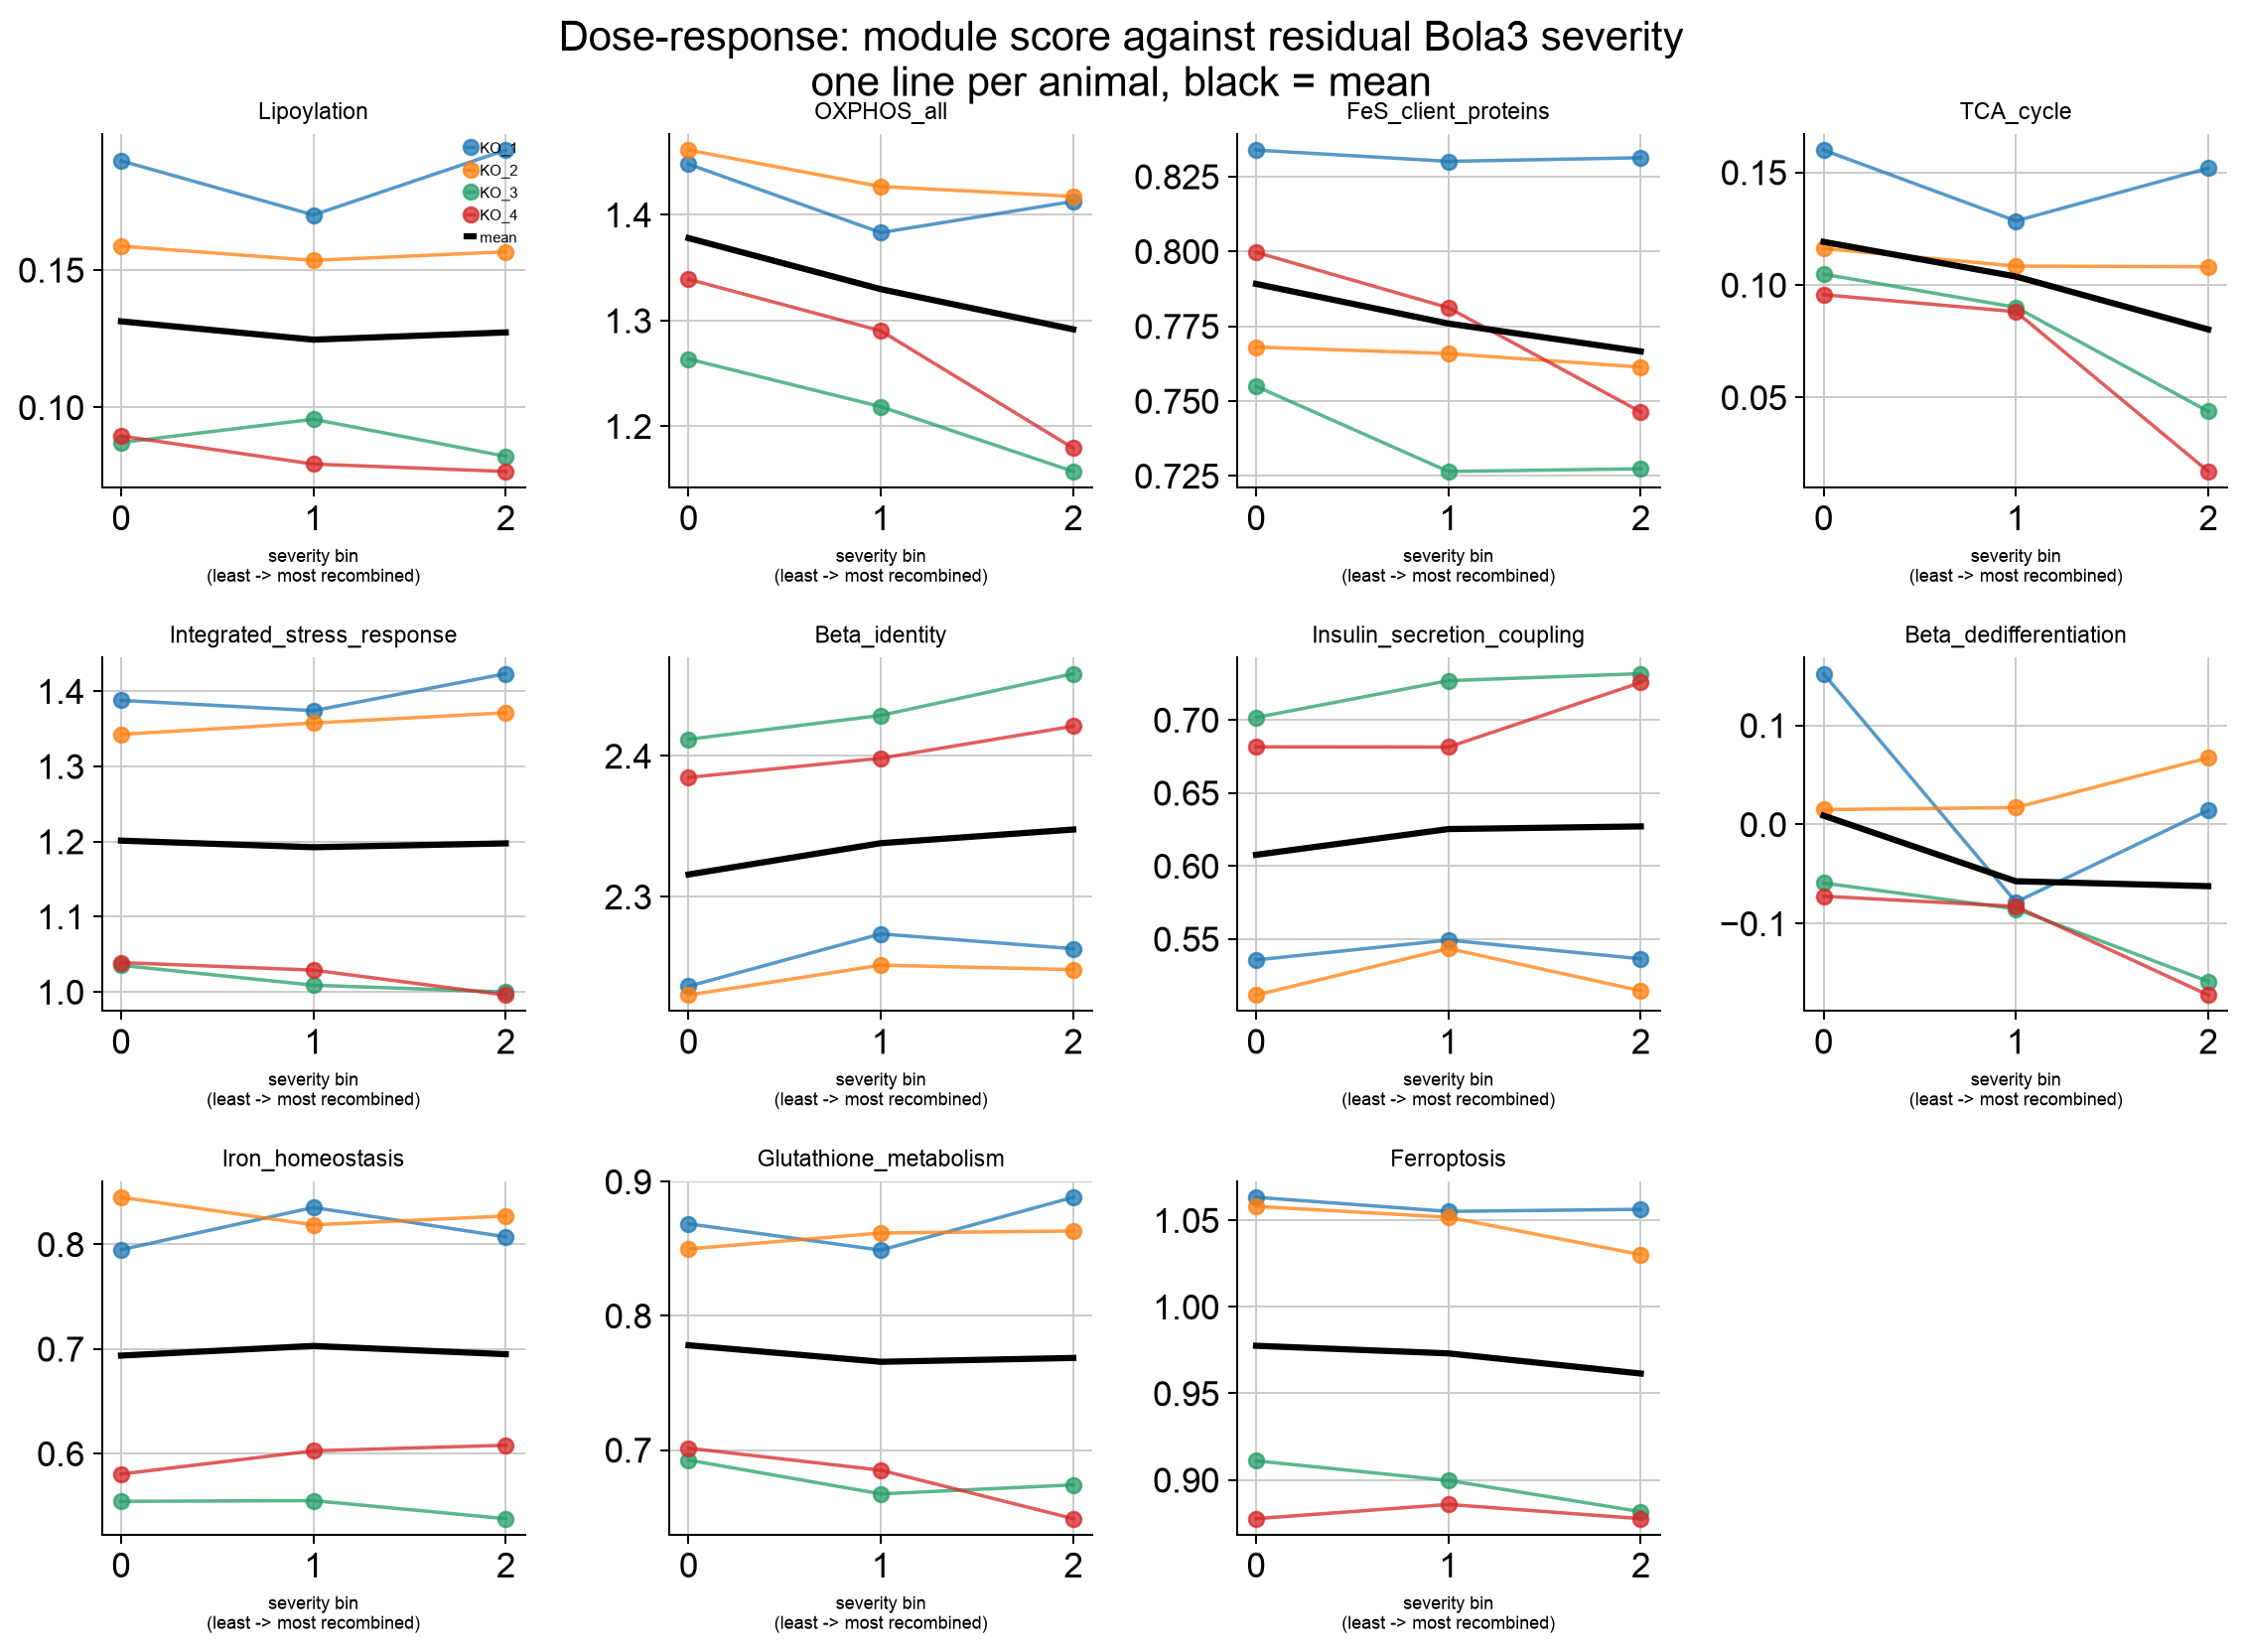

In [7]:
key = ["Lipoylation", "OXPHOS_all", "FeS_client_proteins", "TCA_cycle",
       "Integrated_stress_response", "Beta_identity",
       "Insulin_secretion_coupling", "Beta_dedifferentiation",
       "Iron_homeostasis", "Glutathione_metabolism", "Ferroptosis"]
key = [k for k in key if f"m_{k}" in pdata.obs.columns]

fig = plot_dose_response(pdata, key, bin_key="severity_bin", sample_key="mouse_id",
                         ncols=4)
fig.suptitle("Dose-response: module score against residual Bola3 severity\n"
             "one line per animal, black = mean", y=1.03)
fig.savefig(cfg.FIG_DIR / "03c_dose_response.png", dpi=300, bbox_inches="tight")

### How to read this

**Consistent slopes across all four animals are the result.** Each mouse
provides its own internal gradient, so a trend that repeats in every animal
cannot be explained by between-animal variation, by batch, or by the systemic
consequences of glucose intolerance — all of which are constant *within* a
mouse.

Check the direction against the a-priori predictions: lipoylation, OXPHOS, TCA
and insulin secretion coupling should fall with increasing severity; the
integrated stress response and dedifferentiation should rise.

A flat line for a module you predicted would move is informative too. If
lipoylation is flat while the ISR rises, the stress response is not being driven
through the lipoylation defect and the mechanism needs rethinking.


**Result analysis from 3c.2 to 3c.4** What the within-animal dose-response shows

The metabolic gradient is real and clean. Ordering KO beta cells by residual Bola3 within each animal, these decline monotonically with severity at FDR < 0.05: OXPHOS (all complexes), TCA cycle, FeS_client_proteins, glycolysis. That's your core mechanistic result — cells with less Bola3 have lower oxidative metabolism — and it's non-circular (those genes aren't the binning variable). FeS_assembly_core is the strongest hit (p=2×10⁻⁶) but it's partly circular — it contains Bola3, which is the binning variable — so cite OXPHOS/TCA as your clean evidence and treat FeS_assembly_core as a built-in positive control.

Two housekeeping notes: ignore the spearman_rho/p_spearman columns — with only 3 bins they're degenerate (always ±1 or ±0.5, p=0). Trust slope_per_bin, p_slope, and FDR_slope.

Why ferroptosis / iron / GSH look flat here — and it's not the answer

Iron_homeostasis (p=0.91), Glutathione_metabolism (p=0.50), Ferroptosis (tiny slope), Lipoylation (p=0.52), and ISR (p=0.82) are all flat in this test. But look at the plot panels for iron/GSH/ferroptosis: the four animals separate into a higher pair and a lower pair, with flat within-animal slopes. That means their variance is between animals, not within — and the severity design uses animal as a blocking factor, which structurally removes exactly that between-animal signal. So this analysis cannot see a between-animal ferroptosis effect by construction. It's the wrong test for these signatures, not a negative result.

Two more reads worth stating honestly:

Lipoylation flat (predicted down) and ISR flat / Oxidative_stress down (predicted up) — consistent with survivor bias: the cells that mounted acute lethal stress died, so surviving cells show the metabolic scar (OXPHOS↓) but not ongoing stress. This is the same reason your in vitro assays (acute) see ferroptosis while 8-month survivors are quieter.

### The test that actually addresses ferroptosis — across animals, with the alpha control

This regresses each animal's signature score against its recombination rate (WT anchored at 0), separately for beta (cell-autonomous axis) and alpha (systemic control).

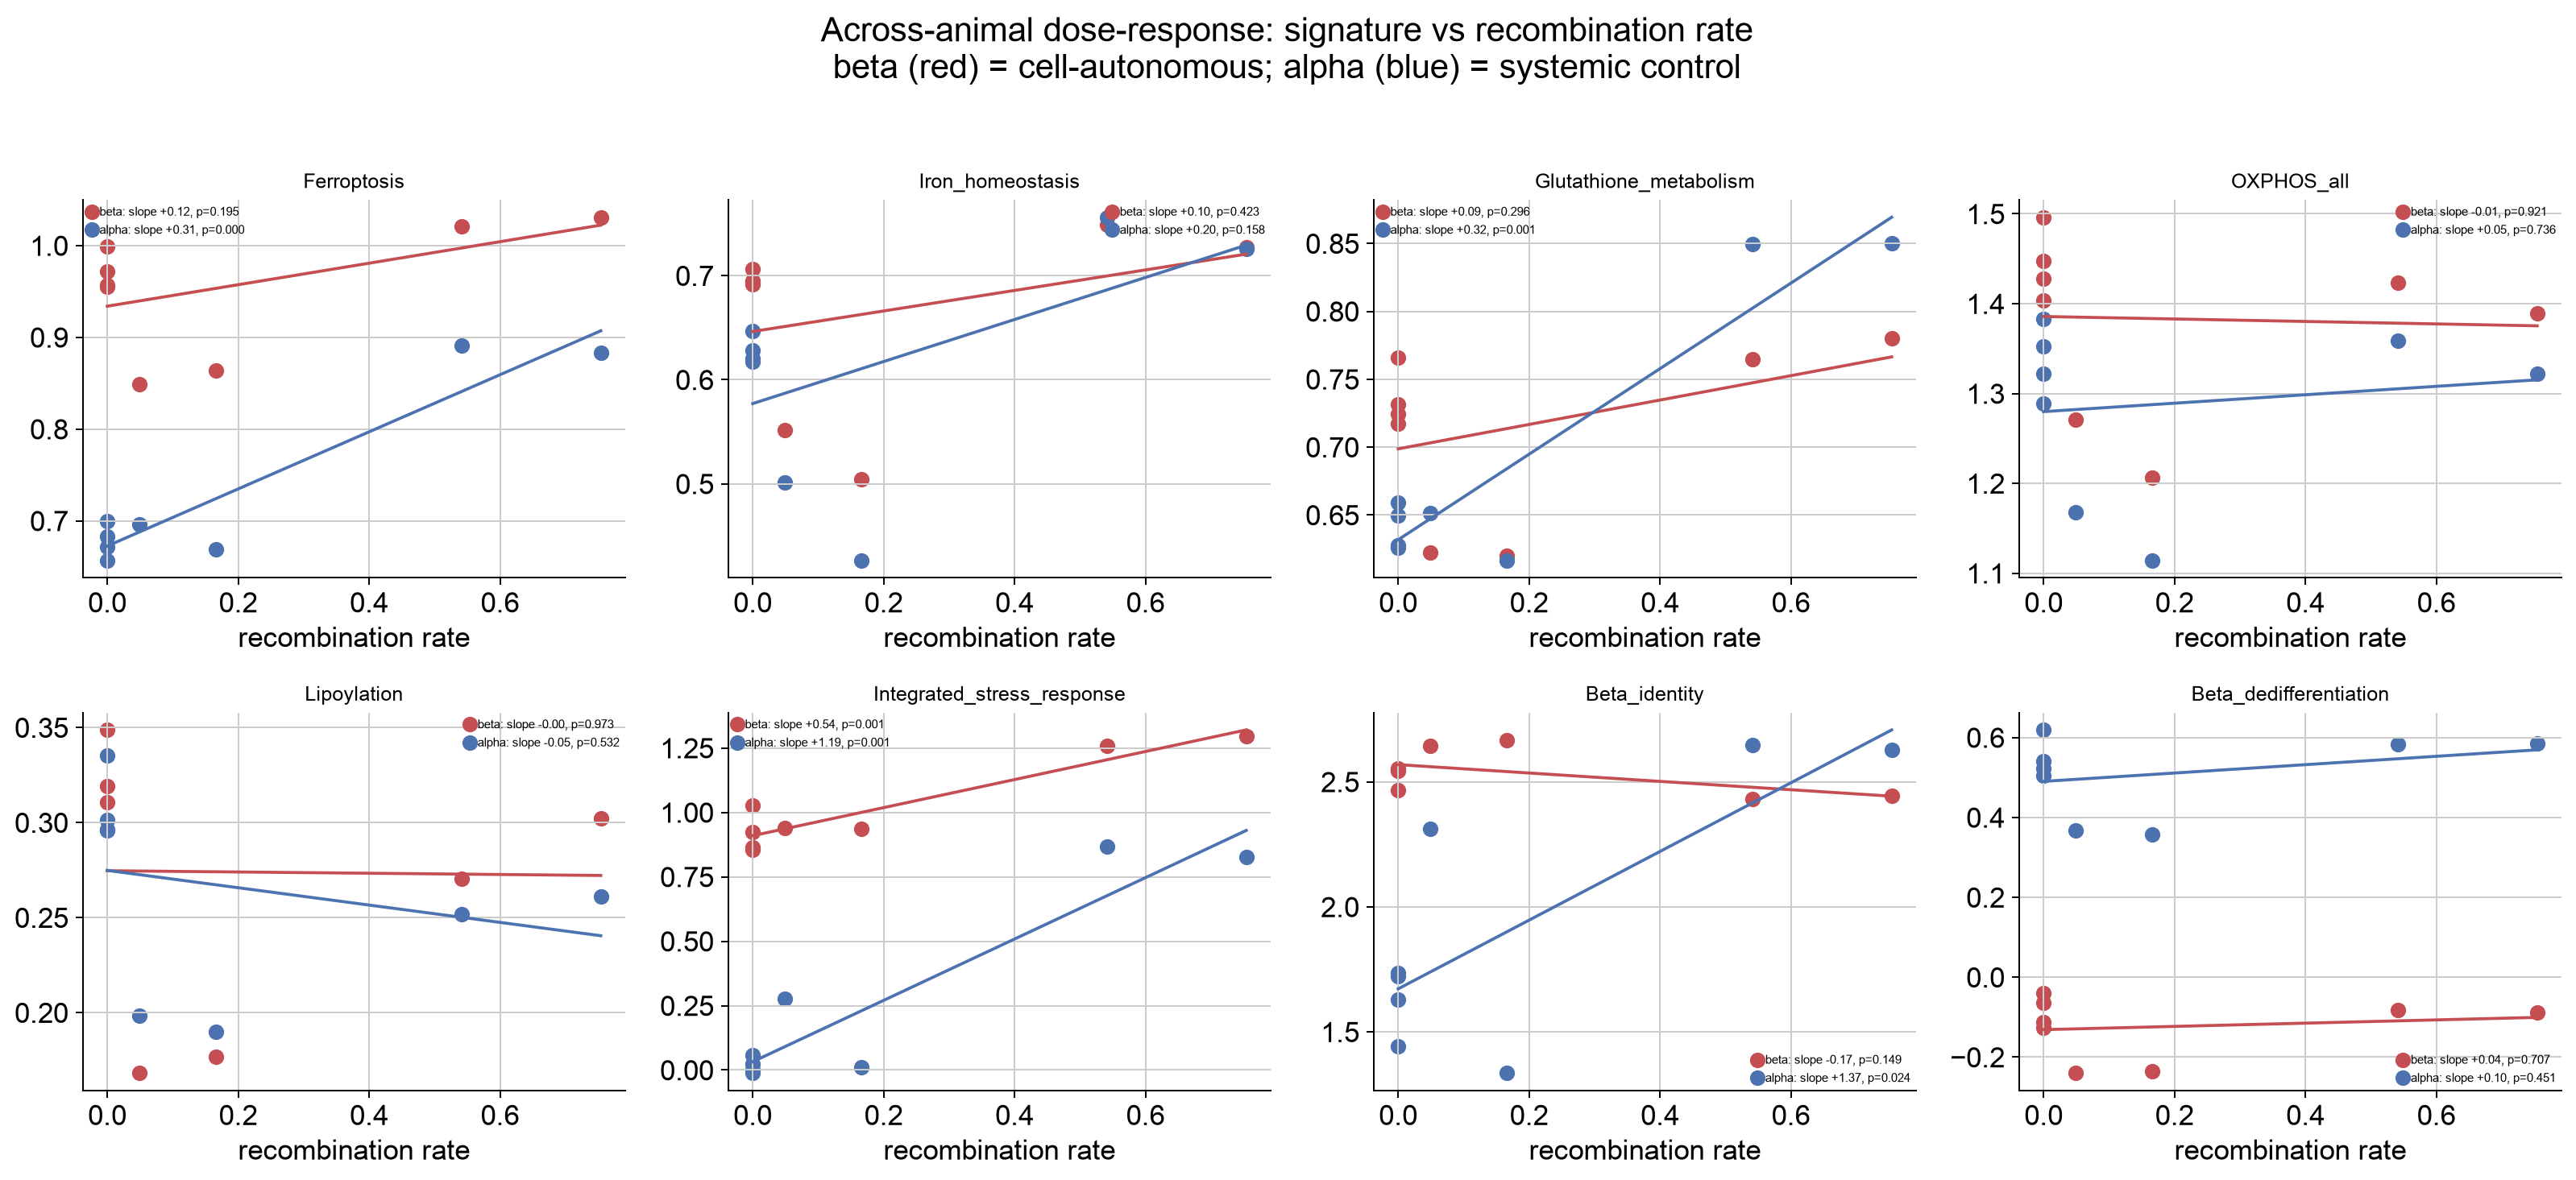

slope                   p          
cell_type                      alpha      beta     alpha      beta
set                                                               
Beta_dedifferentiation      0.104693  0.040657  0.451031  0.707276
Beta_identity               1.373568 -0.167314  0.024412  0.148669
Ferroptosis                 0.311089  0.117195  0.000438  0.194670
Glutathione_metabolism      0.315024  0.089828  0.000591  0.295814
Integrated_stress_response  1.190764  0.544629  0.000810  0.000698
Iron_homeostasis            0.201906  0.098599  0.158254  0.423389
Lipoylation                -0.045590 -0.003300  0.531610  0.972649
OXPHOS_all                  0.046925 -0.013745  0.735625  0.921274

In [12]:
import numpy as np, pandas as pd, scanpy as sc, decoupler as dc
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import linregress
from bola3_gene_sets import GENE_SETS, filter_sets

FOCUS = ["Ferroptosis", "Iron_homeostasis", "Glutathione_metabolism", "OXPHOS_all",
         "Lipoylation", "Integrated_stress_response", "Beta_identity", "Beta_dedifferentiation"]
meta = adata.obs.drop_duplicates("sample_id").set_index("sample_id")[["recomb_rate", "genotype"]]

def per_sample_scores(cell_type):
    sub = adata[adata.obs.cell_type == cell_type].copy()
    pb = dc.pp.pseudobulk(sub, sample_col="sample_id", groups_col=None, mode="sum", layer="counts")
    sc.pp.normalize_total(pb, target_sum=1e6); sc.pp.log1p(pb)
    sets = filter_sets({k: GENE_SETS[k] for k in FOCUS if k in GENE_SETS},
                       pb.var_names, min_genes=5, verbose=False)
    for name, genes in sets.items():
        sc.tl.score_genes(pb, genes, score_name=f"m_{name}", random_state=cfg.RANDOM_SEED)
    # pseudobulk already carries recomb_rate & genotype (constant per sample)
    if "recomb_rate" not in pb.obs.columns:
        pb.obs = pb.obs.join(meta)
    return pb.obs, list(sets)

beta_df, setnames = per_sample_scores("beta")
alpha_df, _ = per_sample_scores("alpha")

rows = []
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, s in zip(axes.flat, setnames):
    col = f"m_{s}"
    for df, ct, color in [(beta_df, "beta", "#C44E52"), (alpha_df, "alpha", "#4C72B0")]:
        x = df["recomb_rate"].astype(float).values; y = df[col].astype(float).values
        lr = linregress(x, y)
        ax.scatter(x, y, c=color, s=45, label=f"{ct}: slope {lr.slope:+.2f}, p={lr.pvalue:.3f}")
        xs = np.array([0, x.max()]); ax.plot(xs, lr.intercept + lr.slope * xs, c=color, lw=1.5)
        rows.append({"set": s, "cell_type": ct, "slope": lr.slope, "p": lr.pvalue, "r": lr.rvalue})
    ax.set_title(s, fontsize=10); ax.set_xlabel("recombination rate"); ax.legend(fontsize=6, frameon=False)
fig.suptitle("Across-animal dose-response: signature vs recombination rate\n"
             "beta (red) = cell-autonomous; alpha (blue) = systemic control", y=1.02)
sns.despine(fig); fig.tight_layout()
fig.savefig(cfg.FIG_DIR / "03c_across_animal_dose_response.png", dpi=300, bbox_inches="tight")
plt.show()

across = pd.DataFrame(rows)
across.to_csv(cfg.TABLE_DIR / "03c_across_animal_dose_response.csv", index=False)
display(across.pivot(index="set", columns="cell_type", values=["slope", "p"]))

### Checking whether the alpha cells are acquiring beta cell genes or is it just Ins expression coming from dying beta cells

In [13]:
import numpy as np, pandas as pd, scanpy as sc
from scipy.stats import linregress

meta = adata.obs.drop_duplicates("sample_id").set_index("sample_id")["recomb_rate"]
def slope_vs_rate(cell_type, genes):
    sub = adata[adata.obs.cell_type == cell_type].copy()
    g = [x for x in genes if x in adata.var_names]
    sc.tl.score_genes(sub, g, score_name="sig", random_state=cfg.RANDOM_SEED)
    d = sub.obs.groupby("sample_id", observed=True)["sig"].mean()
    d = pd.DataFrame({"sig": d, "rate": meta.reindex(d.index)}).dropna()
    lr = linregress(d["rate"], d["sig"])
    return lr.slope, lr.pvalue

BETA_TF = ["Pdx1", "Nkx6-1", "Mafa", "Neurod1"]      # not ambient-prone
BETA_AMBIENT = ["Ins1", "Ins2"]                       # ambient-prone
ALPHA_ID = ["Gcg", "Arx", "Mafb"]
for ct in ["alpha", "delta", "endothelial"]:
    for label, genes in [("beta_TF", BETA_TF), ("ambient_Ins", BETA_AMBIENT), ("alpha_id", ALPHA_ID)]:
        s, p = slope_vs_rate(ct, genes)
        print(f"{ct:12s} {label:12s} slope {s:+.3f}  p={p:.3f}")

alpha        beta_TF      slope -0.011  p=0.903
alpha        ambient_Ins  slope +2.111  p=0.026
alpha        alpha_id     slope -0.353  p=0.016
delta        beta_TF      slope +0.012  p=0.740
delta        ambient_Ins  slope +1.478  p=0.045
delta        alpha_id     slope +0.701  p=0.025
endothelial  beta_TF      slope +0.059  p=0.071
endothelial  ambient_Ins  slope +1.780  p=0.087
endothelial  alpha_id     slope +0.230  p=0.004


It's a negative for transdifferentiation — but an informative one. The decisive comparison:

alpha beta_TF (Pdx1/Nkx6-1/Mafa): slope −0.011, p=0.90 — completely flat. True alpha-to-beta transdifferentiation requires activating the beta transcription factors. They are not induced. So there's no evidence of a genuine beta program in alpha cells.
alpha ambient_Ins (Ins1/Ins2): +2.11, p=0.026 — up. The only thing rising is insulin itself, the most ambient-prone transcript in the islet.
The clincher: endothelial ambient_Ins: +1.78. Endothelial cells physically cannot make insulin or transdifferentiate to beta — yet their insulin signal rises with recombination rate just like alpha's. That can only be ambient contamination from dying beta cells. Delta shows the same (+1.48).

So "beta identity emerging in alpha" is ambient insulin leakage, not transdifferentiation. The earlier Beta_identity slope of +1.37 in alpha was Ins1/2 ambient, not a real program — exactly the artifact we flagged. Don't put transdifferentiation in the paper; it won't survive this test, and a reviewer would run precisely this control.

Two useful things fall out of it, though:

The alpha_id down in alpha (−0.35, p=0.016) is also mostly ambient — as more beta-derived RNA floods the droplets in high-recombination animals, each alpha cell's own Gcg/Arx/Mafb gets diluted after normalization. Note that alpha_id goes up in delta and endothelial (ambient Gcg leaking in). So don't read the alpha decrease as real alpha dedifferentiation either — it's the same contamination in the other direction.
The silver lining: ambient insulin scaling with recombination rate is an indirect readout of beta-cell death proportional to knockout burden. More recombination → more beta lysis → more ambient insulin everywhere. That's a soft, independent corroboration of the cell-autonomous death phenotype — and it retroactively explains why the across-animal ferroptosis "systemic" signal was confounded: a good chunk of it was ambient.

Bottom line across all three of your questions: the western value doesn't affect results; the alpha "beta identity" is ambient, not plasticity; and trimming the ferroptosis set won't help because the limitation is ambient/systemic structure, not gene noise. The scRNA-seq gives you the cell-autonomous metabolic lesion (within-animal OXPHOS/Fe-S) and the death phenotype (beta loss + ambient-insulin proxy); the ferroptosis mechanism is your in vitro data's job. That's a clean, honest, multi-modal story.

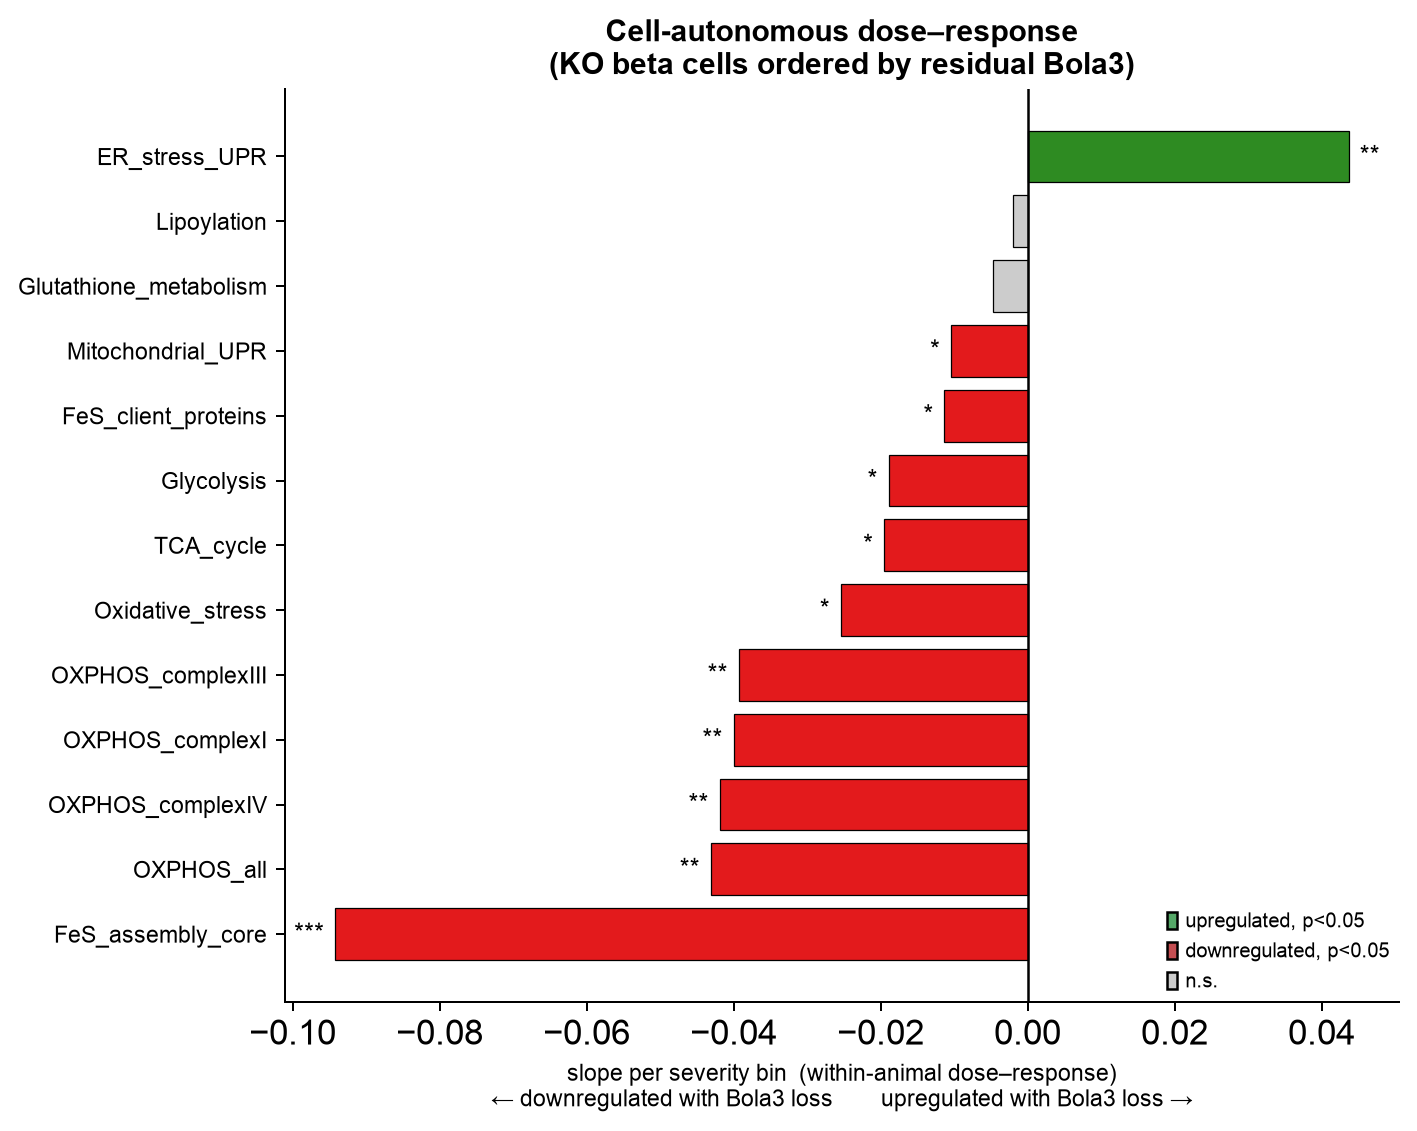

In [18]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.patches import Patch

DROP = {"Beta_identity", "Insulin_secretion_coupling", "Iron_homeostasis",
        "Beta_disallowed", "Integrated_stress_response", "Apoptosis",
        "Ferroptosis", "Beta_dedifferentiation"}

dr = pd.read_csv(cfg.TABLE_DIR / "03c_dose_response.csv")
dr = dr[~dr["gene_set"].isin(DROP)].sort_values("slope_per_bin").reset_index(drop=True)

def stars(p): return "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""

sig = dr["p_slope"] < 0.05
colors = ["#cccccc" if not s else ("#2E8B22" if up else "#E31A1C")   # up=green, down=red
          for s, up in zip(sig, dr["slope_per_bin"] > 0)]

fig, ax = plt.subplots(figsize=(8, 6.5))
ax.grid(False)
y = np.arange(len(dr))
ax.barh(y, dr["slope_per_bin"], color=colors, edgecolor="k", linewidth=0.5)
ax.set_yticks(y); ax.set_yticklabels(dr["gene_set"], fontsize=9)
ax.axvline(0, color="k", lw=1)
ax.set_xlabel("slope per severity bin  (within-animal dose–response)\n"
              "← downregulated with Bola3 loss        upregulated with Bola3 loss →", fontsize=9)
ax.set_title("Cell-autonomous dose–response\n(KO beta cells ordered by residual Bola3)",
             fontsize=12, fontweight="bold")

for yi, (slope, p) in enumerate(zip(dr["slope_per_bin"], dr["p_slope"])):
    s = stars(p)
    if s:
        ax.text(slope + (0.0015 if slope >= 0 else -0.0015), yi, s,
                va="center", ha="left" if slope >= 0 else "right", fontsize=10)

handles = [Patch(facecolor="#55A868", edgecolor="k", label="upregulated, p<0.05"),
           Patch(facecolor="#C44E52", edgecolor="k", label="downregulated, p<0.05"),
           Patch(facecolor="#cccccc", edgecolor="k", label="n.s.")]
ax.legend(handles=handles, frameon=False, fontsize=8, loc="lower right")
sns.despine(); fig.tight_layout()
fig.savefig(cfg.FIG_DIR / "03c_dose_response_slopes.png", dpi=300, bbox_inches="tight")
fig.savefig(cfg.FIG_DIR / "03c_dose_response_slopes.pdf", bbox_inches="tight")
plt.show()

beta subset: n=48876, cell_types=['beta', 'beta_bihormonal']


,genotype,recomb_rate,bola3_cp10k,pct_detected
sample_id,,,,
6763,WT,0.000,0.626,84.527
6764,WT,0.000,0.610,83.370
6766,WT,0.000,0.606,76.417
6768,WT,0.000,0.609,82.219
6785,KO,0.049,0.689,73.265
6772,KO,0.166,0.575,77.213
6754,KO,0.541,0.463,63.649
6751,KO,0.754,0.411,63.066


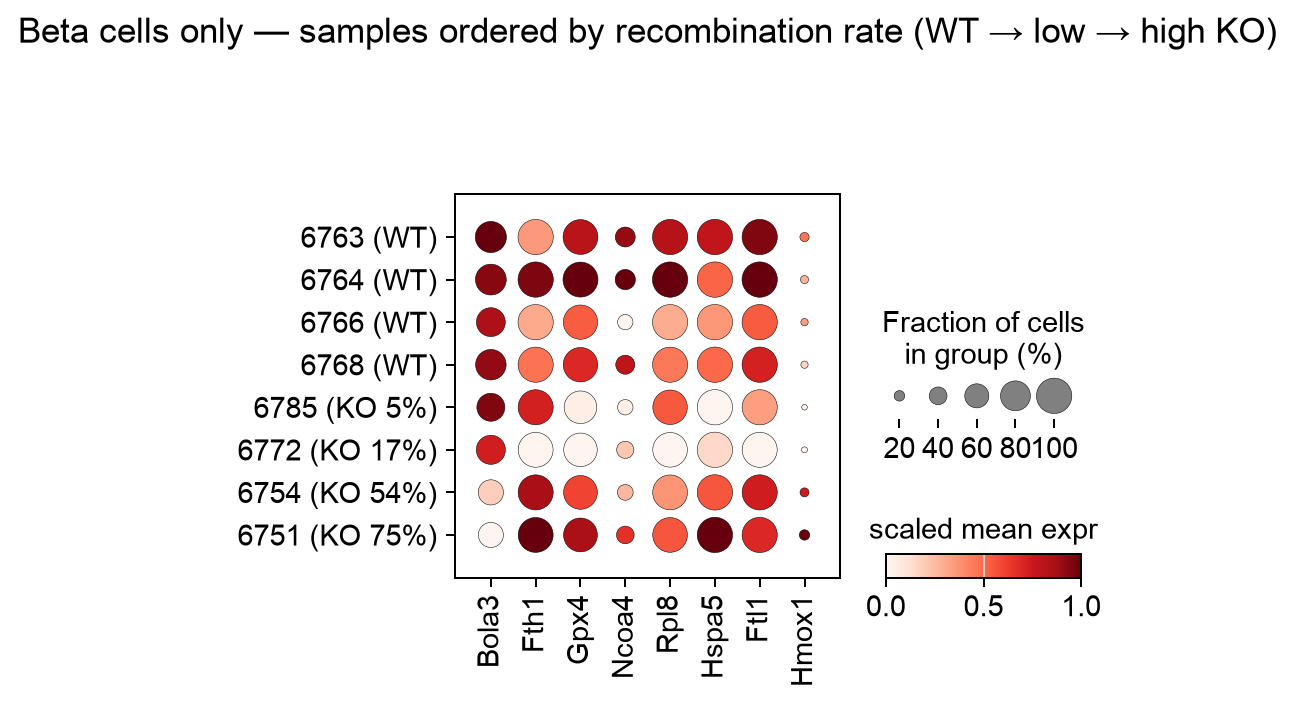

In [25]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.sparse as sp
import scanpy as sc
import pandas as pd

GENES = ["Bola3", "Fth1", "Gpx4", "Ncoa4", "Rpl8", "Hspa5", "Ftl1", "Hmox1"]  # <-- your list (keep Bola3)
LAYER = None
SCALE = True

# ---- BETA CELLS ONLY ----
sub = adata[adata.obs["cell_type"].isin(["beta", "beta_bihormonal"])].copy()
print(f"beta subset: n={sub.n_obs}, cell_types={sorted(sub.obs['cell_type'].unique())}")

# ---- sanity: is Bola3 actually reduced across samples (beta only)? ----
Xc = sub.layers["counts"] if "counts" in sub.layers else sub.X
j = sub.var_names.get_loc("Bola3")
b = np.asarray(Xc[:, j].todense()).ravel() if sp.issparse(Xc) else np.asarray(Xc[:, j]).ravel()
sub.obs["_bola3_cp10k"] = 1e4 * b / np.maximum(np.asarray(Xc.sum(1)).ravel(), 1)
tab = (sub.obs.groupby("sample_id", observed=True)
       .agg(genotype=("genotype", "first"), recomb_rate=("recomb_rate", "first"),
            bola3_cp10k=("_bola3_cp10k", "mean"),
            pct_detected=("_bola3_cp10k", lambda x: 100 * (x > 0).mean()))
       .sort_values("recomb_rate"))
display(tab.round(3))

# ---- dotplot, samples ordered by recombination rate ----
genes = [g for g in GENES if g in adata.var_names]
meta = adata.obs.drop_duplicates("sample_id").set_index("sample_id")
order = meta.sort_values("recomb_rate").index.astype(str).tolist()
def lab(s):
    g = meta.loc[s, "genotype"]
    return f"{s} ({g} {meta.loc[s,'recomb_rate']*100:.0f}%)" if g == "KO" else f"{s} (WT)"
labels = {s: lab(s) for s in order}
sub.obs["sample_lab"] = pd.Categorical(sub.obs["sample_id"].astype(str).map(labels),
                                       categories=[labels[s] for s in order], ordered=True)

sc.pl.dotplot(sub, genes, groupby="sample_lab", layer=LAYER, cmap="Reds",
              standard_scale="var", colorbar_title="scaled mean expr",
              title="Beta cells only — samples ordered by recombination rate (WT → low → high KO)",
              show=False)
plt.savefig(cfg.FIG_DIR / "custom_panel_beta_by_sample_scaled.png", dpi=300, bbox_inches="tight")
plt.show()

beta subset: n=48876, cell_types=['beta', 'beta_bihormonal']


,genotype,recomb_rate,bola3_cp10k,pct_detected
sample_id,,,,
6763,WT,0.000,0.626,84.527
6764,WT,0.000,0.610,83.370
6766,WT,0.000,0.606,76.417
6768,WT,0.000,0.609,82.219
6785,KO,0.049,0.689,73.265
6772,KO,0.166,0.575,77.213
6754,KO,0.541,0.463,63.649
6751,KO,0.754,0.411,63.066


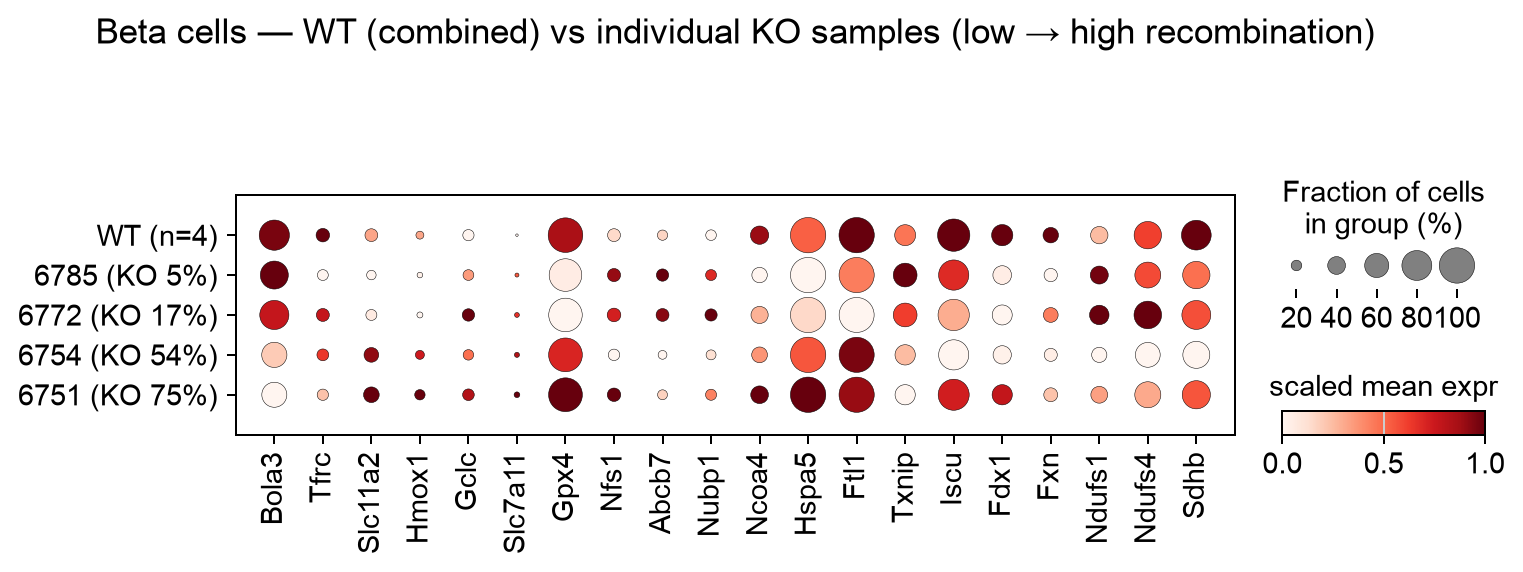

In [44]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.sparse as sp
import scanpy as sc
import pandas as pd

GENES = ["Bola3", 
         "Tfrc", "Slc11a2", "Hmox1", "Gclc","Slc7a11", "Gpx4","Nfs1", "Abcb7","Nubp1","Ncoa4","Hspa5","Hmox1"    # Upregulated panel for iron & Glutathione homeostasis,FeS cluster synthesis, OxPhos
          "Fth1", "Ftl1", "Txnip", "Iscu", "Fdx1","Fxn","Ndufs1", "Ndufs4","Sdhb",              # Downregulated panel for iron & Glutathione homeostasis,FeS cluster synthesis, OxPhos
          ]  # keep Bola3
LAYER = None
SCALE = True

# ---- BETA CELLS ONLY ----
sub = adata[adata.obs["cell_type"].isin(["beta", "beta_bihormonal"])].copy()
print(f"beta subset: n={sub.n_obs}, cell_types={sorted(sub.obs['cell_type'].unique())}")

# ---- sanity: Bola3 across samples (beta only) ----
Xc = sub.layers["counts"] if "counts" in sub.layers else sub.X
j = sub.var_names.get_loc("Bola3")
b = np.asarray(Xc[:, j].todense()).ravel() if sp.issparse(Xc) else np.asarray(Xc[:, j]).ravel()
sub.obs["_bola3_cp10k"] = 1e4 * b / np.maximum(np.asarray(Xc.sum(1)).ravel(), 1)
tab = (sub.obs.groupby("sample_id", observed=True)
       .agg(genotype=("genotype", "first"), recomb_rate=("recomb_rate", "first"),
            bola3_cp10k=("_bola3_cp10k", "mean"),
            pct_detected=("_bola3_cp10k", lambda x: 100 * (x > 0).mean()))
       .sort_values("recomb_rate"))
display(tab.round(3))

# ---- dotplot: WT combined, KO samples separate (ordered by recombination rate) ----
genes = [g for g in GENES if g in adata.var_names]
meta = adata.obs.drop_duplicates("sample_id").set_index("sample_id")
meta.index = meta.index.astype(str)

def lab(s):
    if meta.loc[s, "genotype"] == "WT":
        return "WT (n=4)"
    return f"{s} (KO {meta.loc[s, 'recomb_rate'] * 100:.0f}%)"

ko_samples = meta[meta.genotype == "KO"].sort_values("recomb_rate").index.tolist()
cat_order = ["WT (n=4)"] + [lab(s) for s in ko_samples]          # WT first, then KO low→high

sub.obs["sample_lab"] = pd.Categorical(
    sub.obs["sample_id"].astype(str).map({s: lab(s) for s in meta.index}),
    categories=cat_order, ordered=True)

sc.pl.dotplot(sub, genes, groupby="sample_lab", layer=LAYER, cmap="Reds",
              standard_scale="var" if SCALE else None,
              colorbar_title="scaled mean expr" if SCALE else "mean expr",
              title="Beta cells — WT (combined) vs individual KO samples (low → high recombination)",
              show=False)
plt.savefig(cfg.FIG_DIR / "custom_panel_beta_WTcombined_by_KO.png", dpi=300, bbox_inches="tight")
plt.show()

### Iron homeostasis genes subsetting for Bola3 KO cells acriss bin2 computed in 3c.3

KO beta cells: 24933
severity
bin0 escaper-like       8311
bin1 mid                8311
bin2 most-recombined    8311
Name: count, dtype: int64


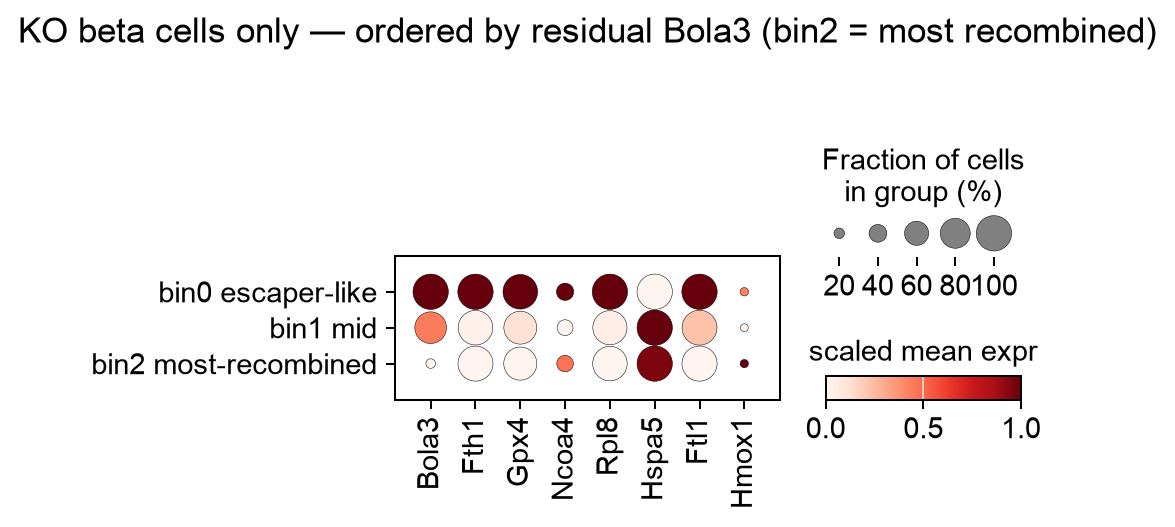

In [30]:
import matplotlib.pyplot as plt
import scanpy as sc

GENES = ["Bola3", "Fth1", "Gpx4", "Ncoa4", "Rpl8", "Hspa5", "Ftl1", "Hmox1"]   # your panel
LAYER = None
SCALE = True    # keep False = absolute; True min-max exaggerates (the trap from before)

# KO beta cells only, ordered by residual Bola3 (bin2 = most recombined = most KO)
sub = adata[(adata.obs["cell_type"].isin(["beta", "beta_bihormonal"]))
            & (adata.obs["genotype"] == "KO")
            & (adata.obs["severity_bin"].notna())].copy()
lab = {0: "bin0 escaper-like", 1: "bin1 mid", 2: "bin2 most-recombined"}
sub.obs["severity"] = pd.Categorical(sub.obs["severity_bin"].astype(int).map(lab),
                                     categories=list(lab.values()), ordered=True)
print(f"KO beta cells: {sub.n_obs}"); print(sub.obs["severity"].value_counts())

genes = [g for g in GENES if g in adata.var_names]
sc.pl.dotplot(sub, genes, groupby="severity", layer=LAYER, cmap="Reds",
              standard_scale="var" if SCALE else None,
              colorbar_title="scaled mean expr" if SCALE else "mean expr",
              title="KO beta cells only — ordered by residual Bola3 (bin2 = most recombined)",
              show=False)
plt.savefig(cfg.FIG_DIR / "ferroptosis_KO_beta_by_severity_dotplot.png", dpi=300, bbox_inches="tight")
plt.show()

grp
WT beta                      22863
KO bin0 (escaper-like)        8311
KO bin2 (most-recombined)     8311
Name: count, dtype: int64


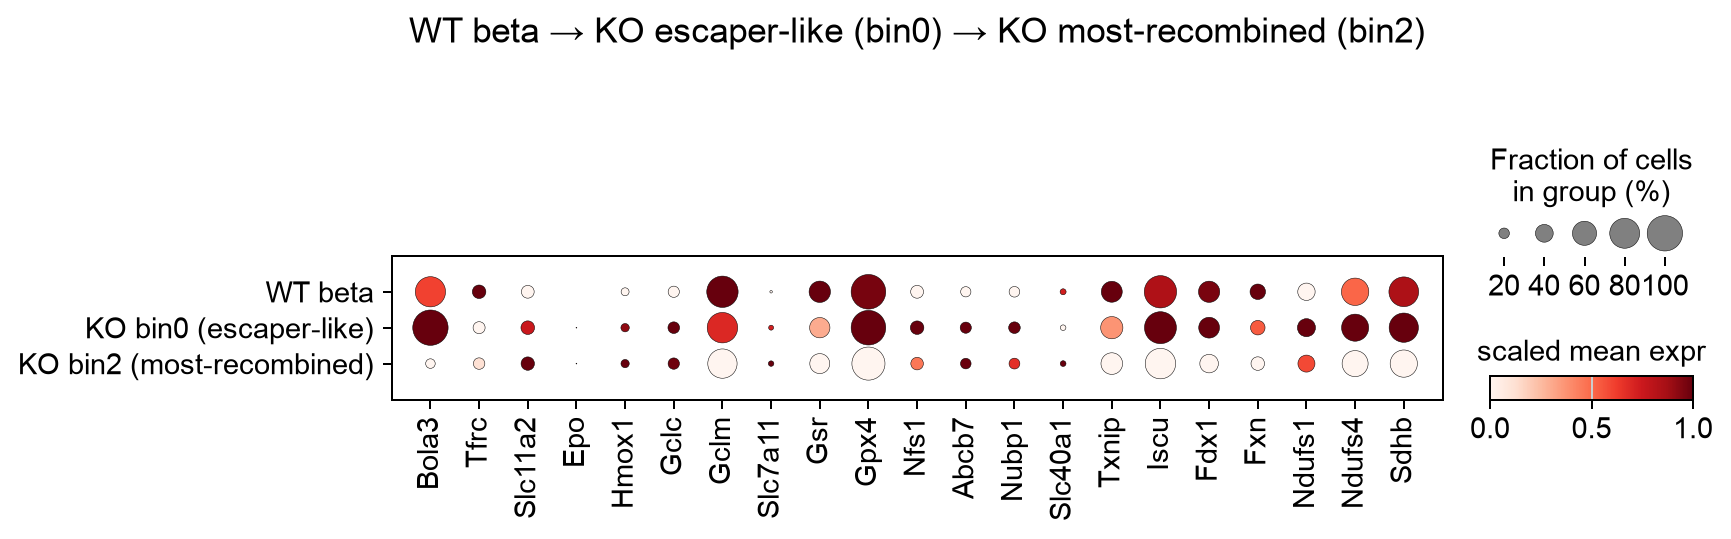

In [42]:
import matplotlib.pyplot as plt
import scanpy as sc
import pandas as pd

GENES = ["Bola3", 
         "Tfrc", "Slc11a2", "Epo", "Hmox1", "Gclc", "Gclm","Slc7a11", "Gsr", "Gpx4","Nfs1", "Abcb7","Nubp1",    # Upregulated panel for iron & Glutathione homeostasis,FeS cluster synthesis, OxPhos
          "Slc40a1", "Fth", "Ftl", "Txnip", "Iscu", "Fdx1", "Fdx2","Fxn","Ndufs1", "Ndufs4","Sdhb"              # Downregulated panel for iron & Glutathione homeostasis,FeS cluster synthesis, OxPhos
        ]    
                                                                   

LAYER = None
SCALE = True    # absolute; keep False (min-max exaggerates)

beta = adata[adata.obs["cell_type"] == "beta"].copy()
grp = pd.Series(index=beta.obs_names, dtype=object)
grp[beta.obs["genotype"] == "WT"] = "WT beta"
grp[(beta.obs["genotype"] == "KO") & (beta.obs["severity_bin"] == 0)] = "KO bin0 (escaper-like)"
grp[(beta.obs["genotype"] == "KO") & (beta.obs["severity_bin"] == 2)] = "KO bin2 (most-recombined)"
beta = beta[grp.notna()].copy()
order = ["WT beta", "KO bin0 (escaper-like)", "KO bin2 (most-recombined)"]
beta.obs["grp"] = pd.Categorical(grp.dropna().values, categories=order, ordered=True)
print(beta.obs["grp"].value_counts())

genes = [g for g in GENES if g in adata.var_names]
sc.pl.dotplot(beta, genes, groupby="grp", layer=LAYER, cmap="Reds",
              standard_scale="var" if SCALE else None,
              colorbar_title="scaled mean expr" if SCALE else "mean expr",
              title="WT beta → KO escaper-like (bin0) → KO most-recombined (bin2)",
              show=False)
plt.savefig(cfg.FIG_DIR / "ferroptosis_WT_vs_KO_severity_dotplot.png", dpi=300, bbox_inches="tight")
plt.show()

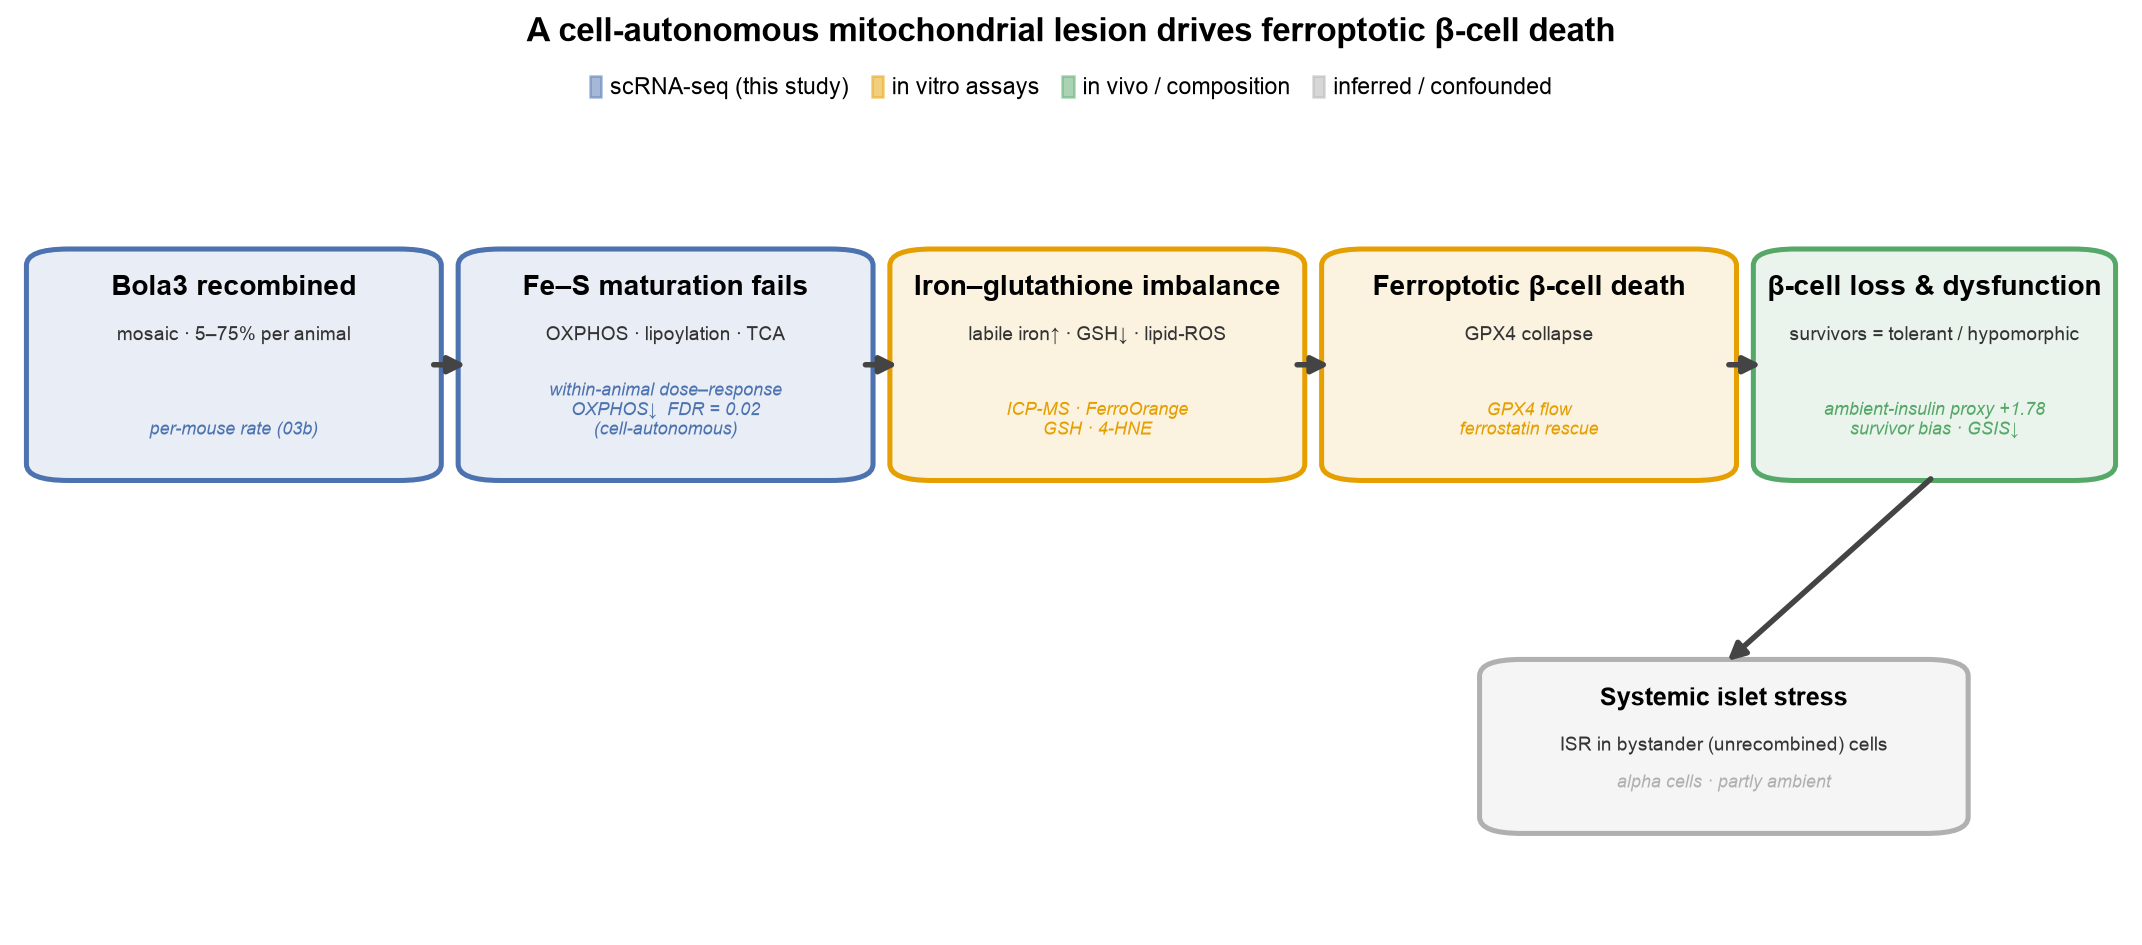

In [14]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Patch

SCRNA, INVITRO, INVIVO, INFERRED = "#4C72B0", "#E69F00", "#55A868", "#B0B0B0"

# (x, y, w, h, title, subtitle, colour, stat)
NODES = [
    (0.01, 0.55, 0.185, 0.27, "Bola3 recombined", "mosaic · 5–75% per animal",
     SCRNA, "per-mouse rate (03b)"),
    (0.215, 0.55, 0.185, 0.27, "Fe–S maturation fails", "OXPHOS · lipoylation · TCA",
     SCRNA, "within-animal dose–response\nOXPHOS↓  FDR = 0.02\n(cell-autonomous)"),
    (0.42, 0.55, 0.185, 0.27, "Iron–glutathione imbalance", "labile iron↑ · GSH↓ · lipid-ROS",
     INVITRO, "ICP-MS · FerroOrange\nGSH · 4-HNE"),
    (0.625, 0.55, 0.185, 0.27, "Ferroptotic β-cell death", "GPX4 collapse",
     INVITRO, "GPX4 flow\nferrostatin rescue"),
    (0.83, 0.55, 0.16, 0.27, "β-cell loss & dysfunction", "survivors = tolerant / hypomorphic",
     INVIVO, "ambient-insulin proxy +1.78\nsurvivor bias · GSIS↓"),
]
SYSTEMIC = (0.70, 0.12, 0.22, 0.20, "Systemic islet stress",
            "ISR in bystander (unrecombined) cells", INFERRED, "alpha cells · partly ambient")

fig, ax = plt.subplots(figsize=(15, 6)); ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis("off")

def node(x, y, w, h, title, sub, c, stat, fs=11):
    for fc, ls in [(c, 0.12), ("none", 1)]:
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.006,rounding_size=0.02",
                     lw=2, edgecolor=c, facecolor=fc if fc != "none" else "none",
                     alpha=ls if fc != "none" else 1))
    cx = x + w / 2
    ax.text(cx, y + h - 0.05, title, ha="center", fontsize=fs, fontweight="bold")
    ax.text(cx, y + h - 0.105, sub, ha="center", fontsize=7.5, color="#333")
    ax.text(cx, y + 0.05, stat, ha="center", fontsize=7, color=c, style="italic")

for n in NODES: node(*n)
node(*SYSTEMIC, fs=10)

def arrow(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="-|>", lw=2.2, color="#444"))
yc = 0.55 + 0.27 / 2
for i in range(len(NODES) - 1):
    arrow(NODES[i][0] + NODES[i][2], yc, NODES[i + 1][0], yc)
arrow(NODES[4][0] + NODES[4][2] / 2, 0.55, SYSTEMIC[0] + SYSTEMIC[2] / 2, SYSTEMIC[1] + SYSTEMIC[3])

handles = [Patch(facecolor=c, alpha=0.5, edgecolor=c, label=l) for c, l in
           [(SCRNA, "scRNA-seq (this study)"), (INVITRO, "in vitro assays"),
            (INVIVO, "in vivo / composition"), (INFERRED, "inferred / confounded")]]
ax.legend(handles=handles, loc="upper center", ncol=4, frameon=False,
          bbox_to_anchor=(0.5, 1.05), fontsize=9)
ax.set_title("A cell-autonomous mitochondrial lesion drives ferroptotic β-cell death",
             fontsize=13, fontweight="bold", pad=26)

fig.savefig(cfg.FIG_DIR / "model_multimodal_story.png", dpi=300, bbox_inches="tight")
fig.savefig(cfg.FIG_DIR / "model_multimodal_story.pdf", bbox_inches="tight")
plt.show()

### 3c.5 Bounding the survivor bias

The cells you sequenced are those that survived 8 months. If the most severely
affected died, every effect measured here understates the population effect.
This cannot be resolved from the data, but it can be bounded and stated.

In [45]:
beta_frac_wt = (adata.obs.query("genotype == 'WT'").cell_type == "beta").mean()
beta_frac_ko = (adata.obs.query("genotype == 'KO'").cell_type == "beta").mean()
implied_loss = max(0.0, 1 - beta_frac_ko / max(beta_frac_wt, 1e-9))
print(f"beta fraction: WT {beta_frac_wt:.3f} -> KO {beta_frac_ko:.3f}")
print(f"implied beta cell loss: {100 * implied_loss:.1f}%\n")

if len(dr):
    worst = dr.iloc[0]
    for k, v in survivor_bias_bound(implied_loss, worst.slope_per_bin * (N_BINS - 1)).items():
        print(f"  {k}: {v}")

beta fraction: WT 0.572 -> KO 0.642
implied beta cell loss: 0.0%

  beta_cells_lost: 0.0
  observed_effect: -0.188
  true_effect_if_lost_cells_matched_worst_bin: -0.188
  note: with 0% of beta cells lost, the surviving-cell effect understates the population effect; the true magnitude is bounded below by the observed value and plausibly up to 1.00x it


---
## What to report

Lead with the **dose-response**, not a two-group contrast:

> "Beta cells from *Pdx1-CreER; Bola3^fl/fl^* animals were ordered by residual
> *Bola3* expression and binned into terciles within each animal. Module scores
> for protein lipoylation and oxidative phosphorylation decreased monotonically
> with increasing severity in all four animals (slope per bin ..., p = ...),
> while integrated stress response scores increased. Because each animal
> contributes its own internal gradient, this trend is independent of
> between-animal variation and of the systemic consequences of glucose
> intolerance."

Then state the three limits plainly:

1. **Allelic mosaicism.** `Bola3^fl/fl` under incomplete Cre yields escaper,
   hypomorphic and null cells. The severity axis orders cells by dosage but does
   not resolve discrete genotypes at the single-cell level.
2. **Survivor bias.** At an 8-month chase, null cells are the most likely to
   have died. Effects reported here derive from surviving, largely hypomorphic
   cells and are lower bounds.
3. **Protein-level corroboration.** The whole-islet western (~50% reduction)
   implies a steeper beta-specific reduction once non-recombined cell types are
   accounted for; §3c.2 gives the arithmetic.

Framing the result as *reduced Bola3 dosage* rather than *loss of Bola3* is both
more accurate and harder to attack — and a dose-response is a stronger claim
than a knockout-versus-control difference in any case.